# Обучение baseline модели

## 1. Подключение библиотек и загрузка данных

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

from matplotlib import pyplot as plt

Фиксируем random_state для воспроизводимости случайных значений.

In [3]:
RANDOM_STATE = 42

Загрузим первый датасет. Это будет rtsd-dataset с Kaggle.

<span style="color:red">**ВНИМАНИЕ!!! ОН ВЕСИТ 17,1Гб !!!**</span>

In [65]:
# Установка библиотеки
# !pip install kagglehub -q

In [4]:
import kagglehub

In [5]:
# Скачивание датасета. Функция возвращает путь к скачанным данным.
path = kagglehub.dataset_download("watchman/rtsd-dataset")

print("Путь к данным:", path)
# Теперь `path` можно использовать для доступа к файлам датасета

Путь к данным: C:\Users\stepa\.cache\kagglehub\datasets\watchman\rtsd-dataset\versions\3


Этот блок нужен только для того, чтоб ориентироваться в json

In [7]:
import json

In [8]:
with open(f'{path}/train_anno.json', 'r') as f:
    train_anno = json.load(f)

In [9]:
print(list(train_anno.keys()))

['images', 'annotations', 'categories']


In [10]:
print("images      :", train_anno['images'][0])
print("annotations :", train_anno['annotations'][0])
print("categories  :", train_anno['categories'][0])

images      : {'id': 0, 'width': 1280, 'height': 720, 'file_name': 'rtsd-frames/autosave01_02_2012_09_13_33.jpg'}
annotations : {'id': 0, 'image_id': 0, 'category_id': 1, 'area': 324, 'bbox': [649, 376, 18, 18], 'iscrowd': 0}
categories  : {'id': 1, 'name': '2_1'}


In [11]:
categories_df = pd.DataFrame(train_anno['categories'])
annotations_df = pd.DataFrame(train_anno['annotations'])
ann_with_names = annotations_df.merge(categories_df, left_on='category_id', right_on='id', suffixes=('_ann', '_cat'))

In [64]:
# !pip install -q ultralytics grad-cam opencv-python-headless tqdmtorch

In [63]:
# это на случай если установлен torch для cpu, который не видит gpu
# pip uninstall torch torchvision torchaudio -y
# pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124
# весит 2ГБ

In [13]:
import os, json, shutil, random
from pathlib import Path
from collections import defaultdict

import cv2
from tqdm.notebook import tqdm

In [14]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Версия CUDA в сборке PyTorch:", torch.version.cuda)
    print("Имя активной видеокарты:", torch.cuda.get_device_name(0))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "—")


PyTorch version: 2.6.0+cu124
CUDA available: True
Версия CUDA в сборке PyTorch: 12.4
Имя активной видеокарты: NVIDIA GeForce RTX 3060 Laptop GPU
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


Конфигурация путей

In [15]:
DATASET_ROOT = Path(path)
DATASET_IMAGES_ROOT = Path(f'{path}\\rtsd-frames\\')
FRAMES_DIR   = DATASET_ROOT / "rtsd-frames"
OUT_DIR      = Path("./rtsd_yolo")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert (DATASET_ROOT / "train_anno.json").exists(), "train_anno.json не найден"
assert FRAMES_DIR.exists(), "rtsd-frames не найден"
print("OK, датасет найден:", DATASET_ROOT.resolve())

OK, датасет найден: C:\Users\stepa\.cache\kagglehub\datasets\watchman\rtsd-dataset\versions\3


Т.к. у нас датасет COCO то переводим в формат YOLO

In [16]:
with open(DATASET_ROOT / "train_anno.json") as f:
    train_anno = json.load(f)
with open(DATASET_ROOT / "val_anno.json") as f:
    val_anno = json.load(f)

# --- 1. Построение непрерывной карты category_id -> 0..N-1 ---
categories = train_anno["categories"]
cat_ids_sorted = sorted(c["id"] for c in categories)
cat_id_to_yolo = {cid: idx for idx, cid in enumerate(cat_ids_sorted)}
yolo_id_to_name = {cat_id_to_yolo[c["id"]]: c["name"] for c in categories}

# --- 2. Создаём структуру папок YOLO ---
for split in ("train", "val"):
    (OUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

def convert_split(anno: dict, split: str):
    """Переводит COCO-аннотации в YOLO-формат + ссылки на изображения."""
    anns_by_img = defaultdict(list)
    for a in anno["annotations"]:
        if a.get("iscrowd", 0) == 1:      # пропускаем crowd-регионы
            continue
        anns_by_img[a["image_id"]].append(a)

    n_written, n_skipped = 0, 0
    for img in tqdm(anno["images"], desc=f"convert {split}"):
        file_name = img["file_name"]                    # 'rtsd-frames/xxx.jpg'
        base_name = Path(file_name).stem                # 'xxx'
        W, H = img["width"], img["height"]

        # ---- label .txt ----
        label_path = OUT_DIR / "labels" / split / f"{base_name}.txt"
        with open(label_path, "w") as f:
            for a in anns_by_img[img["id"]]:
                x, y, w, h = a["bbox"]
                # Клиппинг к границам изображения
                x = max(0.0, min(x, W)); y = max(0.0, min(y, H))
                w = min(w, W - x);        h = min(h, H - y)
                if w <= 1 or h <= 1:          # отбрасываем вырожденные боксы
                    n_skipped += 1
                    continue
                xc = (x + w / 2) / W
                yc = (y + h / 2) / H
                wn = w / W
                hn = h / H
                cls = cat_id_to_yolo[a["category_id"]]
                f.write(f"{cls} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}\n")
                n_written += 1

        # ---- изображение (симлинк, если ОС позволяет, иначе copy) ----
        src = DATASET_IMAGES_ROOT / file_name
        dst = OUT_DIR / "images" / split / f"{base_name}{src.suffix}"
        if not dst.exists():
            try:
                os.symlink(src.resolve(), dst)
            except (OSError, NotImplementedError):
                shutil.copy(src, dst)
    print(f"{split}: боксов записано={n_written}, пропущено вырожденных={n_skipped}")

convert_split(train_anno, "train")
convert_split(val_anno,   "val")

convert train:   0%|          | 0/54188 [00:00<?, ?it/s]

train: боксов записано=95492, пропущено вырожденных=0


convert val:   0%|          | 0/5000 [00:00<?, ?it/s]

val: боксов записано=8866, пропущено вырожденных=0


Создание data.yaml + быстрая валидация

In [17]:
yaml_content = f"""# RTSD YOLO dataset
path: {OUT_DIR.resolve()}
train: images/train
val:   images/val

nc: {len(categories)}
names:
"""
for i in range(len(categories)):
    yaml_content += f"  {i}: '{yolo_id_to_name[i]}'\n"

(OUT_DIR / "data.yaml").write_text(yaml_content)
print("data.yaml создан:", (OUT_DIR / "data.yaml").resolve())

# --- Быстрый sanity-check: сколько картинок/лейблов реально есть ---
for split in ("train", "val"):
    n_img = len(list((OUT_DIR / "images" / split).glob("*.*")))
    n_lbl = len(list((OUT_DIR / "labels" / split).glob("*.txt")))
    print(f"{split}: images={n_img}, labels={n_lbl}")

data.yaml создан: C:\Users\stepa\Desktop\HSE\Team_project\rtsd_yolo\data.yaml
train: images=54188, labels=54188
val: images=5000, labels=5000


## 2. Обучение YOLO v8 nano

В EDA были сделаны выводы относительно аугментаций. Для обучения отлично подходят аугментации связанные с яркостью и контрастом. В YOLO уже реализованы и сбалансированы эти аугментации, поэтому их значения оставим по-умолчанию (не будем задавать явно). Горизонтальное отражение же для нас вредно и означает снижение качества модели, т.к. знаки при отражении меняют своё значение.
Итого, параметры аугментаций:
* Случайный сдвиг оттенка (Hue) `hsv_h` = 0.015.
* Случайное изменение насыщенности (Saturation) `hsv_s` = 0.7.
* Случайное изменение яркости (Value) `hsv_v` = 0.4
* Случайный поворот `degrees` оставим 0
* Случайный сдвиг изображения `translate` оставим 0.1
* Случайное масштабирование (зум) `scale` оставим 0.5
* Случайное горизонтальное отражение по-умолчанию `fliplr` = 0.5, изменим на 0
* Случайное вертикальное отражение `flipud` оставим 0
* Склейка 4 изображений в одно `mosaic` оставим 1
* Смешивание двух изображений `mixup` оставим 0
* Вставка фрагмента одного изображения в другое `cutmix` оставим 0
* Вставка объектов из других изображений `copy_paste` оставим 0

In [18]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(OUT_DIR / "data.yaml"),
    epochs=30,
    imgsz=640,
    batch=-1,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    project="runs",
    name="yolov8n_rtsd_baseline_aug",
    exist_ok=True,
    patience=10,              # early stopping
    optimizer="AdamW",
    lr0=1e-3,
    cos_lr=True,
    cache=False, 
    amp=True,
    seed=42,
    deterministic=True,
    pretrained=True,
    val=True,
    plots=True,
    verbose=True,
    fliplr=0.0         # убрал случайное горизонтальное отражение
)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.204  Python-3.13.7 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=rtsd_yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.p

## 3. Оценка baseline-метрик

In [19]:
best = YOLO("C:/Users/stepa/Desktop/HSE/Team_project/runs/detect/runs/yolov8n_rtsd_baseline_aug/weights/best.pt")
metrics = best.val(
    data=str(OUT_DIR / "data.yaml"),
    split="val",
    imgsz=640,
    batch=16,
    conf=0.001,               # для честного mAP
    iou=0.6,
    verbose=False,
)

baseline = {
    "mAP50":       float(metrics.box.map50),
    "mAP50-95":    float(metrics.box.map),
    "precision":   float(metrics.box.mp),
    "recall":      float(metrics.box.mr),
    "F1":          float(2 * (metrics.box.mp * metrics.box.mr) / (metrics.box.mp + metrics.box.mr) if (metrics.box.mp + metrics.box.mr) > 0 else 0.0)
}

print("=" * 50)
print("🎯 BASELINE METRICS (YOLOv8n @640, 30 epochs)")
print("=" * 50)
for k, v in baseline.items():
    print(f"  {k:12s}: {v:.4f}")

# сохраняем для сравнения будущих подходов
pd.Series(baseline).to_csv("baseline_metrics.csv", header=["value"])
print("Сохранено в baseline_metrics.csv")

Ultralytics 8.4.204  Python-3.13.7 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,170,129 parameters, 0 gradients, 8.8 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 917.0±177.6 MB/s, size: 84.8 KB)
val: Scanning C:\Users\stepa\Desktop\HSE\Team_project\rtsd_yolo\labels\val.cache... 5000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000 2.3Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 313/313 6.3it/s 49.6s0.1sss
                   all       5000       8866      0.741      0.673      0.753      0.551
Speed: 0.8ms preprocess, 2.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to C:\Users\stepa\Desktop\HSE\Team_project\runs\detect\val-3
🎯 BASELINE METRICS (YOLOv8n @640, 30 epochs)
  mAP50       : 0.7532
  mAP50-95    : 0.5510
  precision   : 0.7412
  recall      : 0.6727
  F1          : 0.7053
Сохранено в baseline_metr

Сохраняем обученную модель

In [20]:
best.save("yolov8n_baseline_aug.pt")

Инференс на отложенной картинке (визуальная проверка)

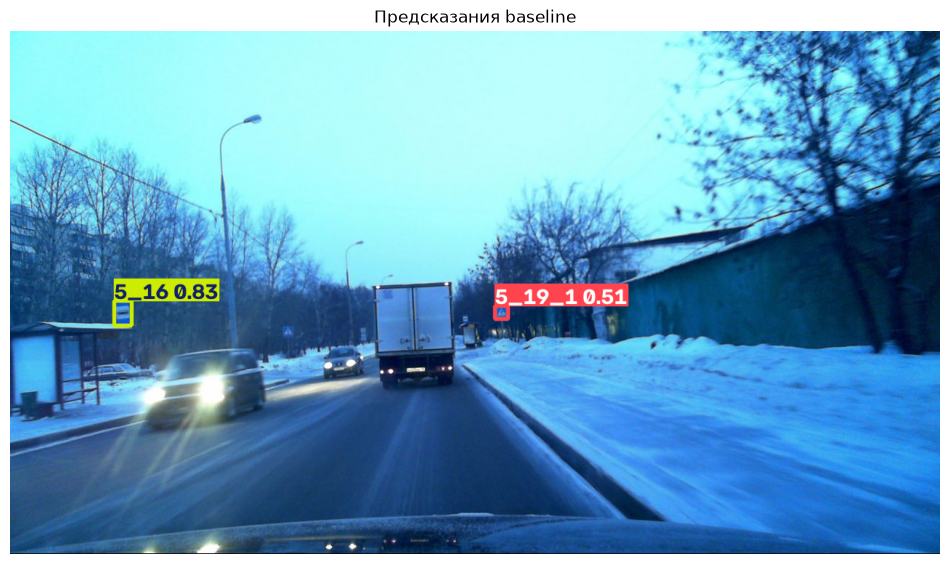

Найдено объектов: 2
Топ-5 по уверенности:
      5_16  conf=0.834
    5_19_1  conf=0.507


In [21]:
# Предсказание на одной картинке из val
test_img = str(next((OUT_DIR / "images" / "val").glob("*.jpg")))
preds = best.predict(source=test_img, imgsz=640, conf=0.25, iou=0.5, verbose=False)
preds[0].plot()                                # рисует боксы
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(preds[0].plot(), cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title("Предсказания baseline"); plt.show()

# Топ-5 уверенных предсказаний с расшифровкой имён классов
if preds[0].boxes is not None:
    boxes = preds[0].boxes
    print(f"Найдено объектов: {len(boxes)}")
    print("Топ-5 по уверенности:")
    conf = boxes.conf.cpu().numpy()
    cls  = boxes.cls.cpu().numpy().astype(int)
    order = conf.argsort()[::-1][:5]
    for j in order:
        print(f"  {best.names[cls[j]]:>8s}  conf={conf[j]:.3f}")